ANT COLONY OPTIMIZATION - NETWORK ROUTING
Source router      : S
Destination router : D
Best route found   : S -> A -> B -> C -> E -> F -> D
Total route cost    : 10
Number of iterations: 80

Dijkstra comparison:
Shortest route     : S -> A -> B -> E -> F -> D
Shortest cost      : 10


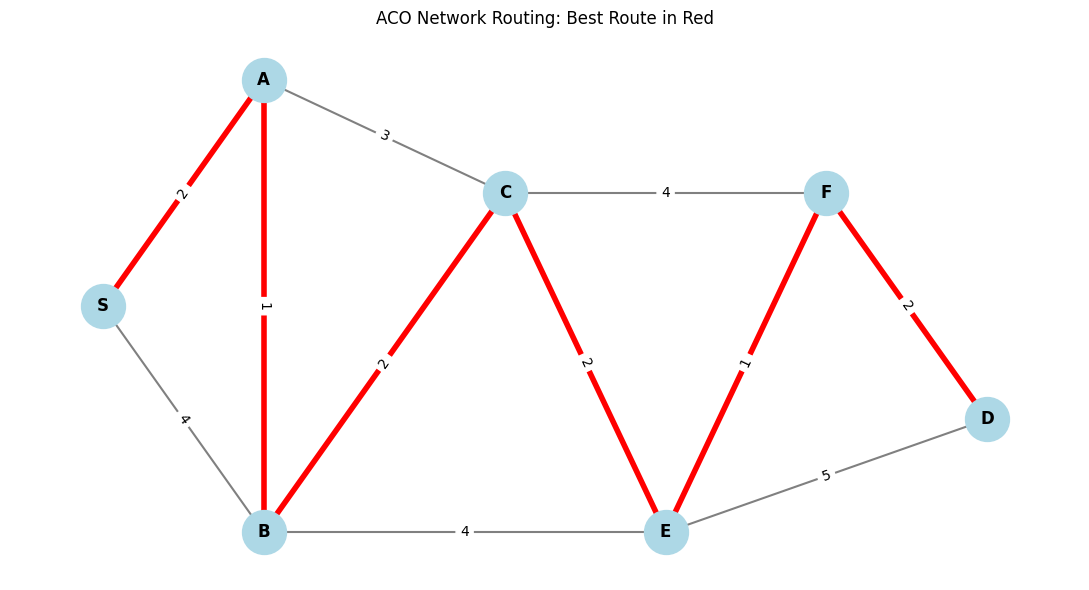

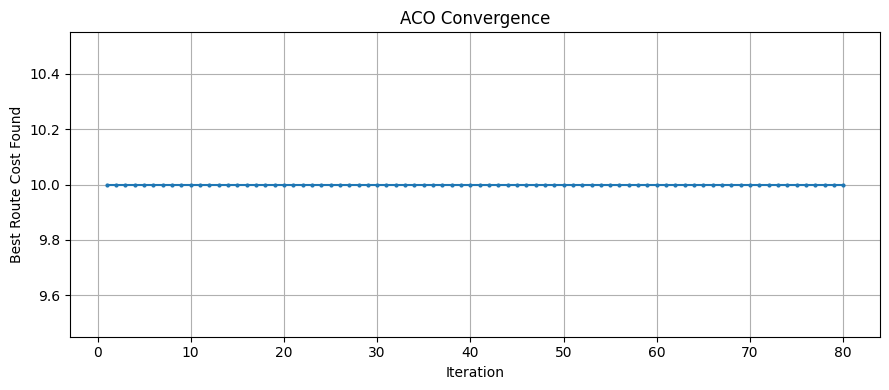


Simulated data packet transmission:
Packet forwarded: S -> A
Packet forwarded: A -> B
Packet forwarded: B -> C
Packet forwarded: C -> E
Packet forwarded: E -> F
Packet forwarded: F -> D
Packet successfully reached destination: D


In [1]:

# Ant Colony Optimization for Computer Network Routing
# Inspired by the ACO routing principles discussed in the IEEE survey paper
# Educational simulation - simplified ACO, not a full AntNet implementation

import random
import networkx as nx
import matplotlib.pyplot as plt

# ------------------------------------------
# 1. CREATE THE COMPUTER NETWORK
# ------------------------------------------

random.seed(42)

G = nx.Graph()

# Routers in the network
routers = ["S", "A", "B", "C", "E", "F", "D"]
G.add_nodes_from(routers)

# Links between routers and their costs
# Cost represents link distance/delay (lower is better)
links = [
    ("S", "A", 2),
    ("S", "B", 4),
    ("A", "B", 1),
    ("A", "C", 3),
    ("B", "C", 2),
    ("B", "E", 4),
    ("C", "E", 2),
    ("C", "F", 4),
    ("E", "F", 1),
    ("E", "D", 5),
    ("F", "D", 2)
]

for u, v, cost in links:
    G.add_edge(u, v, weight=cost)

SOURCE = "S"
DESTINATION = "D"

# ------------------------------------------
# 2. ACO PARAMETERS
# ------------------------------------------

NUM_ANTS = 30
NUM_ITERATIONS = 80

ALPHA = 1.0       # Importance of pheromone
BETA = 2.0        # Importance of link cost
EVAPORATION = 0.30
Q = 100.0         # Pheromone deposit constant
ELITE_WEIGHT = 2.0

# Initialize pheromone on every network link
pheromone = {
    tuple(sorted((u, v))): 1.0
    for u, v in G.edges()
}

def edge_key(u, v):
    return tuple(sorted((u, v)))

def calculate_path_cost(path):
    """Calculate the total cost of a route."""
    return sum(
        G[path[i]][path[i + 1]]["weight"]
        for i in range(len(path) - 1)
    )

# ------------------------------------------
# 3. FORWARD ANT: DISCOVER A ROUTE
# ------------------------------------------

def construct_route():
    current = SOURCE
    path = [current]
    visited = {current}

    while current != DESTINATION:
        candidates = [
            neighbor
            for neighbor in G.neighbors(current)
            if neighbor not in visited
        ]

        if not candidates:
            return None

        # Calculate the probability of choosing each next router
        scores = []

        for neighbor in candidates:
            tau = pheromone[edge_key(current, neighbor)]
            cost = G[current][neighbor]["weight"]

            score = (tau ** ALPHA) * ((1.0 / cost) ** BETA)
            scores.append(score)

        total = sum(scores)
        probabilities = [score / total for score in scores]

        # Probabilistic next-hop selection
        next_router = random.choices(
            candidates,
            weights=probabilities,
            k=1
        )[0]

        path.append(next_router)
        visited.add(next_router)
        current = next_router

    return path

# ------------------------------------------
# 4. BACKWARD ANT: UPDATE PHEROMONES
# ------------------------------------------

best_path = None
best_cost = float("inf")
convergence = []

for iteration in range(NUM_ITERATIONS):
    successful_routes = []

    # Multiple ants independently explore the network
    for ant in range(NUM_ANTS):
        route = construct_route()

        if route is not None:
            cost = calculate_path_cost(route)
            successful_routes.append((route, cost))

            if cost < best_cost:
                best_cost = cost
                best_path = route.copy()

    # Evaporation: reduce old pheromone values
    for edge in pheromone:
        pheromone[edge] *= (1.0 - EVAPORATION)
        pheromone[edge] = max(pheromone[edge], 1e-8)

    # Reinforce links used by successful ants
    for route, cost in successful_routes:
        deposit = Q / cost

        for i in range(len(route) - 1):
            edge = edge_key(route[i], route[i + 1])
            pheromone[edge] += deposit

    # Additional reinforcement for the best route found so far
    if best_path is not None:
        elite_deposit = ELITE_WEIGHT * Q / best_cost

        for i in range(len(best_path) - 1):
            edge = edge_key(best_path[i], best_path[i + 1])
            pheromone[edge] += elite_deposit

    convergence.append(best_cost)

# ------------------------------------------
# 5. DISPLAY RESULTS
# ------------------------------------------

print("=" * 45)
print("ANT COLONY OPTIMIZATION - NETWORK ROUTING")
print("=" * 45)

print("Source router      :", SOURCE)
print("Destination router :", DESTINATION)
print("Best route found   :", " -> ".join(best_path))
print("Total route cost    :", best_cost)
print("Number of iterations:", NUM_ITERATIONS)

# Compare against the exact shortest path for validation
exact_path = nx.shortest_path(
    G, SOURCE, DESTINATION, weight="weight"
)
exact_cost = nx.shortest_path_length(
    G, SOURCE, DESTINATION, weight="weight"
)

print("\nDijkstra comparison:")
print("Shortest route     :", " -> ".join(exact_path))
print("Shortest cost      :", exact_cost)

# ------------------------------------------
# 6. VISUALIZE THE NETWORK AND ROUTE
# ------------------------------------------

positions = {
    "S": (0, 2),
    "A": (1, 3),
    "B": (1, 1),
    "C": (2.5, 2.5),
    "E": (3.5, 1),
    "F": (4.5, 2.5),
    "D": (5.5, 1.5)
}

best_edges = [
    (best_path[i], best_path[i + 1])
    for i in range(len(best_path) - 1)
]

plt.figure(figsize=(11, 6))

nx.draw_networkx_nodes(
    G, positions, node_size=1000,
    node_color="lightblue"
)
nx.draw_networkx_labels(
    G, positions, font_size=12, font_weight="bold"
)
nx.draw_networkx_edges(
    G, positions, width=1.5, edge_color="gray"
)
nx.draw_networkx_edges(
    G, positions, edgelist=best_edges,
    width=4, edge_color="red"
)

edge_labels = nx.get_edge_attributes(G, "weight")
nx.draw_networkx_edge_labels(
    G, positions, edge_labels=edge_labels
)

plt.title("ACO Network Routing: Best Route in Red")
plt.axis("off")
plt.tight_layout()
plt.show()

# ------------------------------------------
# 7. CONVERGENCE GRAPH
# ------------------------------------------

plt.figure(figsize=(9, 4))
plt.plot(
    range(1, NUM_ITERATIONS + 1),
    convergence,
    marker=".",
    markersize=4
)
plt.xlabel("Iteration")
plt.ylabel("Best Route Cost Found")
plt.title("ACO Convergence")
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------
# 8. SIMULATE SENDING A DATA PACKET
# ------------------------------------------

print("\nSimulated data packet transmission:")
for i in range(len(best_path) - 1):
    print(f"Packet forwarded: {best_path[i]} -> {best_path[i + 1]}")

print("Packet successfully reached destination:", DESTINATION)
